Load the dataset


In [1]:
import pandas as pd

df = pd.read_csv("student_marks.csv")


Explore the dataset

In [2]:
print(df.head())
print(df.shape)

   Study_Hours  Exam_Marks
0            1          22
1            2          28
2            3          35
3            4          42
4            5          48
(12, 2)


In [4]:
print(df.describe())

       Study_Hours  Exam_Marks
count    12.000000   12.000000
mean      6.500000   58.166667
std       3.605551   23.755701
min       1.000000   22.000000
25%       3.750000   40.250000
50%       6.500000   58.500000
75%       9.250000   76.750000
max      12.000000   94.000000


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  12 non-null     int64
 1   Exam_Marks   12 non-null     int64
dtypes: int64(2)
memory usage: 324.0 bytes
None


check data quality - missing value and duplicate rows

In [5]:
print(df.isnull().sum())

Study_Hours    0
Exam_Marks     0
dtype: int64


In [7]:
print(df.duplicated().sum())

0


In [9]:
print(df.isna().any())

Study_Hours    False
Exam_Marks     False
dtype: bool


Visualize the relatonship


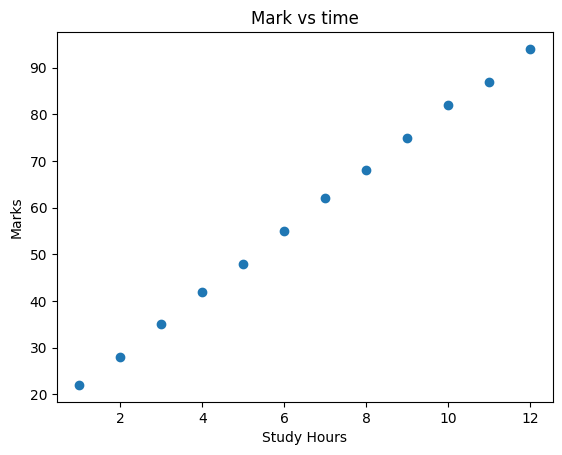

In [11]:
import matplotlib.pyplot as plt

plt.scatter(df['Study_Hours'],df['Exam_Marks'])
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Mark vs time")
plt.show()

Separate features and target

In [13]:
X = df[["Study_Hours"]]
y = df["Exam_Marks"]

Split dataset

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                    random_state=42 , test_size=0.2)

Train the model

In [34]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

model = LinearRegression()

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring='r2'

)
print("CV score",scores)

model.fit(X_train,y_train)



CV score [0.99884853 0.96467923 0.99885306 0.99949822        nan]


c:\Users\A\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6.6]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Study_Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Make predictions - also for unseen data

In [35]:
y_pred = model.predict(X_test)
print(y_pred)



[87.88268156 81.27932961 21.84916201]


In [24]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "predicted": y_pred
})
print(comparison)

    Actual  predicted
10      87  87.882682
9       82  81.279330
0       22  21.849162


In [ ]:
new_data = pd.DataFrame({
    'Study_Hours': [7]
})
prediction = model.predict(new_data)
print(prediction)

[61.46927374]


Evaluate the model


In [37]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import numpy as np
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))

rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("RMSE",rmse)

MAE 0.5847299813780206
MSE 0.44041488509513355
R2 score 0.9994950657368336
RMSE 0.6636376157927861


Intercept & coefficient

A coefficient tells us how much the predicted target changes when an input feature increases by one unit, assuming other features remain constant

The intercept is the predicted value of the target when all input features are zero.

In [30]:
print("Intercept",model.intercept_)
print("Coefficient",model.coef_)

Intercept 15.245810055865938
Coefficient [6.60335196]


Where:
- \(y\) = Predicted exam marks
- \(m\) = Coefficient (6.6)
- \(x\) = Study hours
- \(c\) = Intercept (15)

\[
y = mx + c
\]